# Phase 4 — verified measured results

**Engineering gate complete.** Reviewed 1 November 2026. These saved results are derived from the latest private Kaggle export, which labels its measured run v6. The prepared source is v7; the exact executed Kaggle notebook was not supplied. This public report does not execute a model or include transcripts, private IDs or raw token sequences.

[Full results and interpretation](../docs/PHASE4_RESULTS.md) · [Source notebook](Phase-4B-Kaggle-Smoke-Test.ipynb)


## Measured checks

| Check | Result | Meaning |
|---|---|---|
| Checkpoint/processor | `neurlang/ipa-whisper-base` at `949f7c4e4ee374b5202bc5886f6e4552e5ae2371` | Exact public initialization recorded |
| Frozen target checks | 5,044 passed; zero round-trip, unknown-token or over-limit rows | Existing symbols and combining marks are representable |
| Set-aside target checks | 42 passed; maximum content length 361 | Representation succeeds; labels remain excluded pending review |
| Frozen maximum content length | 358; special-token-inclusive lengths fit 448 | No target truncation needed in this pool |
| Audio/features | 12 nonempty 16 kHz mono clips; finite `[1,80,3000]` features | Processor/audio path works across 0.75–28.82 s |
| Repeat inference | First clip identical | Repeatability checked on this clip/runtime |
| Checkpoint reload | First clip identical | Saving/loading preserves tested inference |
| EOS termination | 6/12 (50%) | These examples terminate before the cap |
| Length limit without EOS | 6/12 (50%); full length 448 | Confirmed cap-limited outputs; preserve in scoring |
| Replacement character | 1/12 contains U+FFFD | Output encoding/termination limitation to record |
| Accuracy | CER not computed | No held-out benchmark score yet |

## Runtime and environment

- **Hardware:** one Tesla T4; **precision:** FP32; **batch:** one; **seed:** 0; attention implementation: SDPA.
- **Versions:** Python 3.13.15; PyTorch 2.11.0+cu128; Transformers 4.57.1; Tokenizers 0.22.2; Hub 0.36.2; SoundFile 0.13.1. Loaded/installed Transformers agree.
- **Generation-loop wall time:** 19.4131 seconds for 128.2169 seconds of audio. Includes a repeated first inference, feature/audio processing and incremental exports; excludes installation, downloads, model loading and checkpoint save/reload. This is not a steady-state speed benchmark.
- **Peak PyTorch CUDA memory:** allocated 380.57 MiB; reserved 408 MiB. These are allocator measurements, not full GPU occupancy or training-memory requirements.
- `pip check` still reports conflicts in other preinstalled Kaggle applications. The measured ASR stack passed, but the overall environment is not dependency-clean.



### 1. Input duration and latency

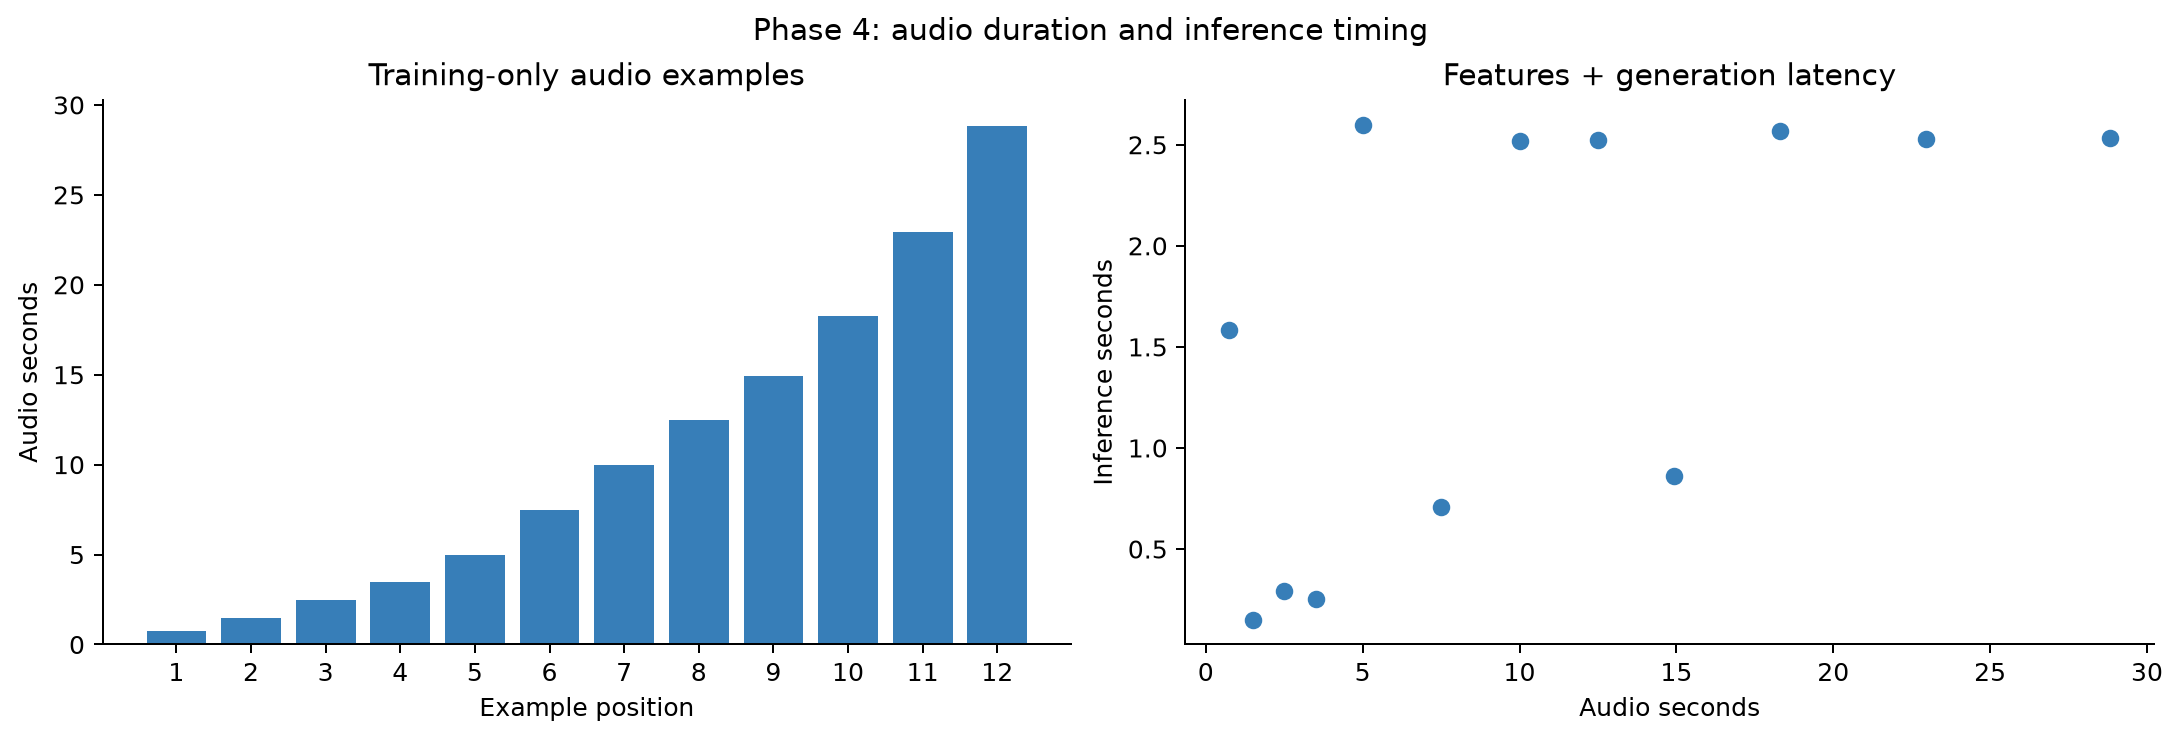

The examples span 0.75–28.82 seconds. Cap-limited predictions cluster near 2.5–2.6 seconds inference despite different audio durations. Decoding workload depends on generated output length as well as audio. The first clip includes warm-up overhead.



### 2. Target capacity and generated sequence lengths

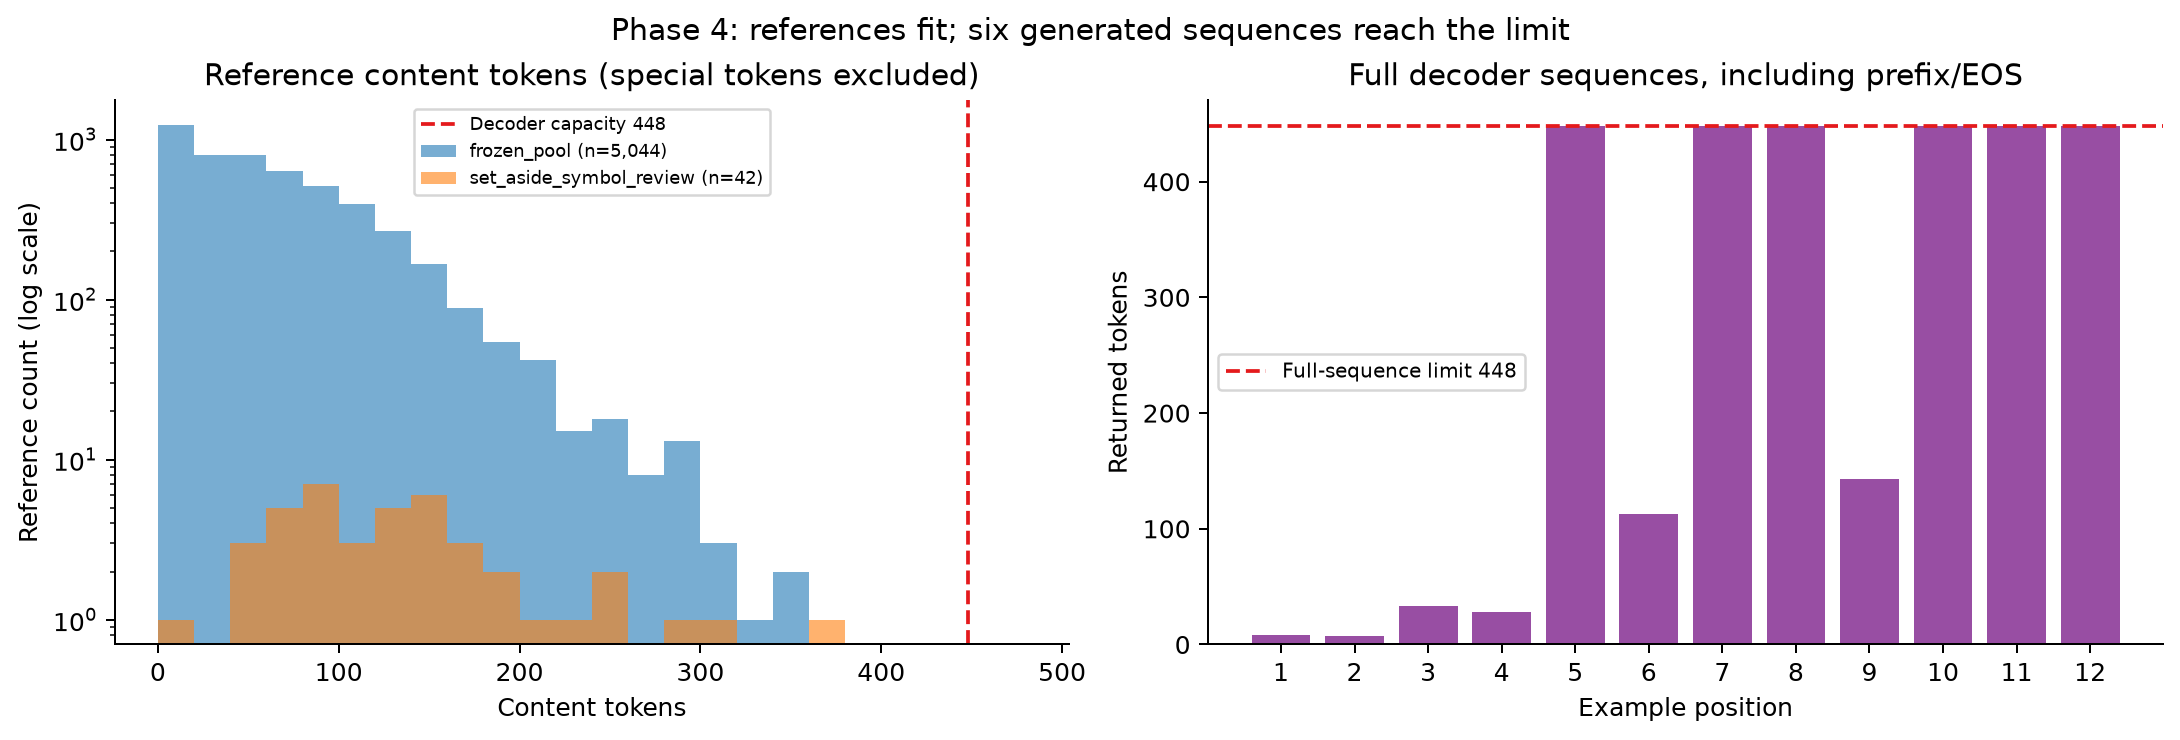

Reference content tokens exclude special tokens; the eligibility check separately includes them. Generated lengths include prefix and EOS where present. Six full sequences reach 448 tokens. The previous 445-content-token observations were those same capped outputs after the three-token prefix was removed.



### 3. Output growth and repetition

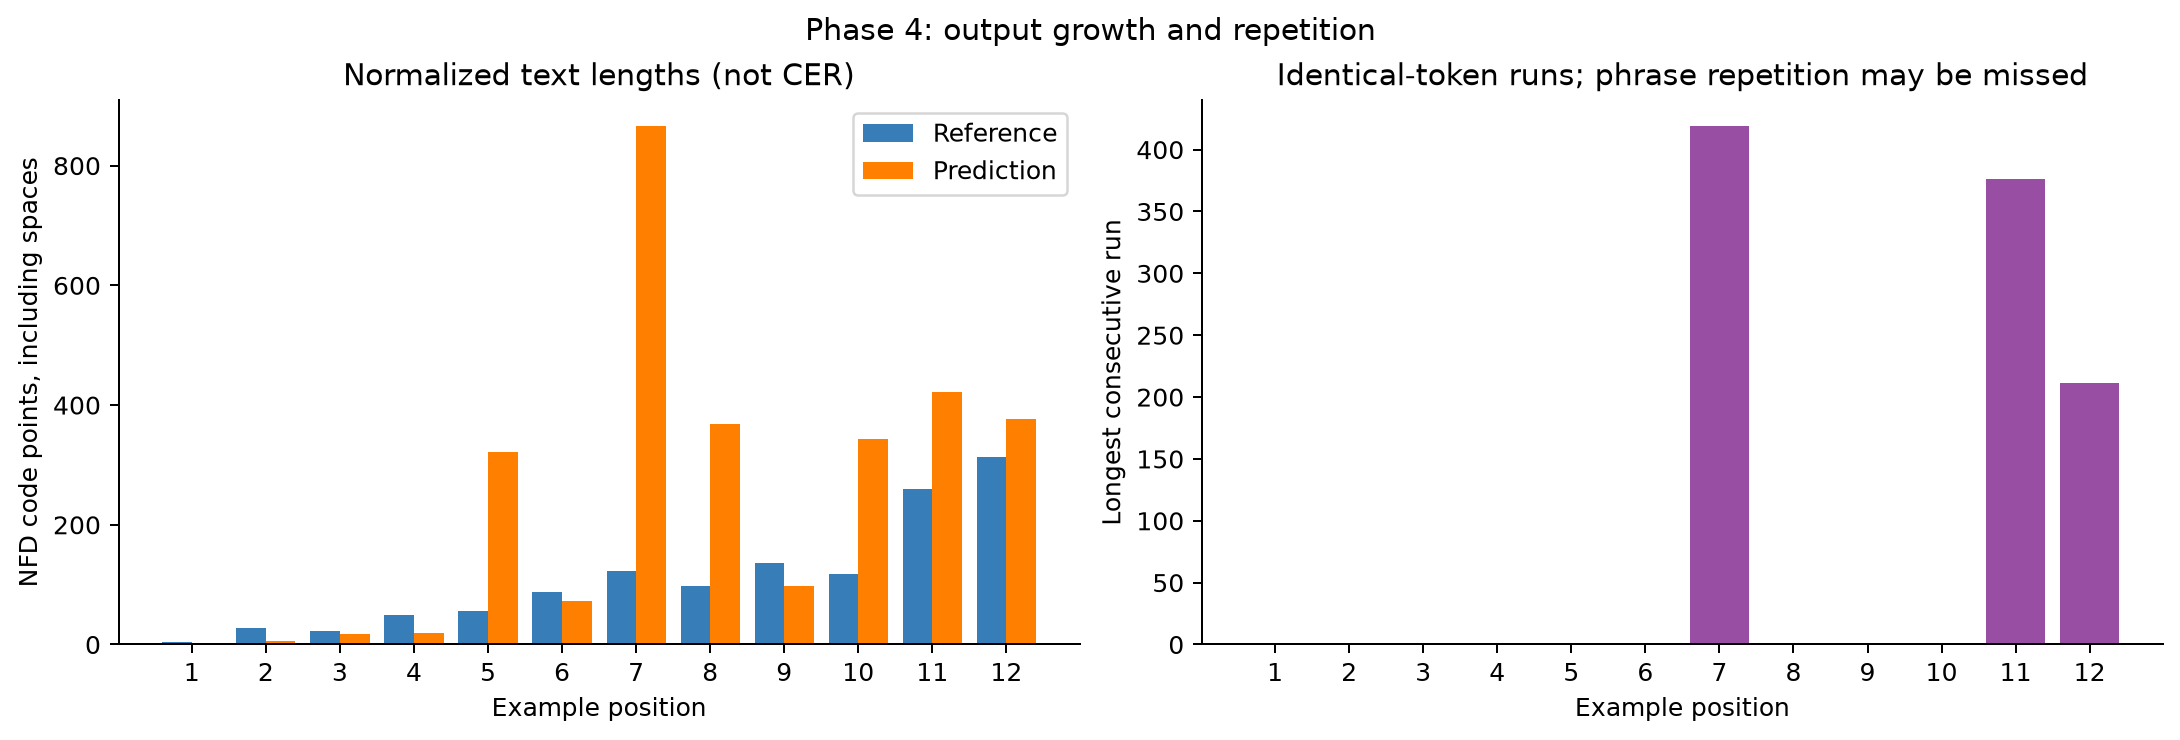

Some predictions are substantially longer than their references. The three longest identical-token runs are **419, 376 and 211**. A run of one does not rule out repeated multi-token phrases. Text length is not CER, and these examples are not a representative accuracy sample.



### 4. Verified stopping and Unicode flags

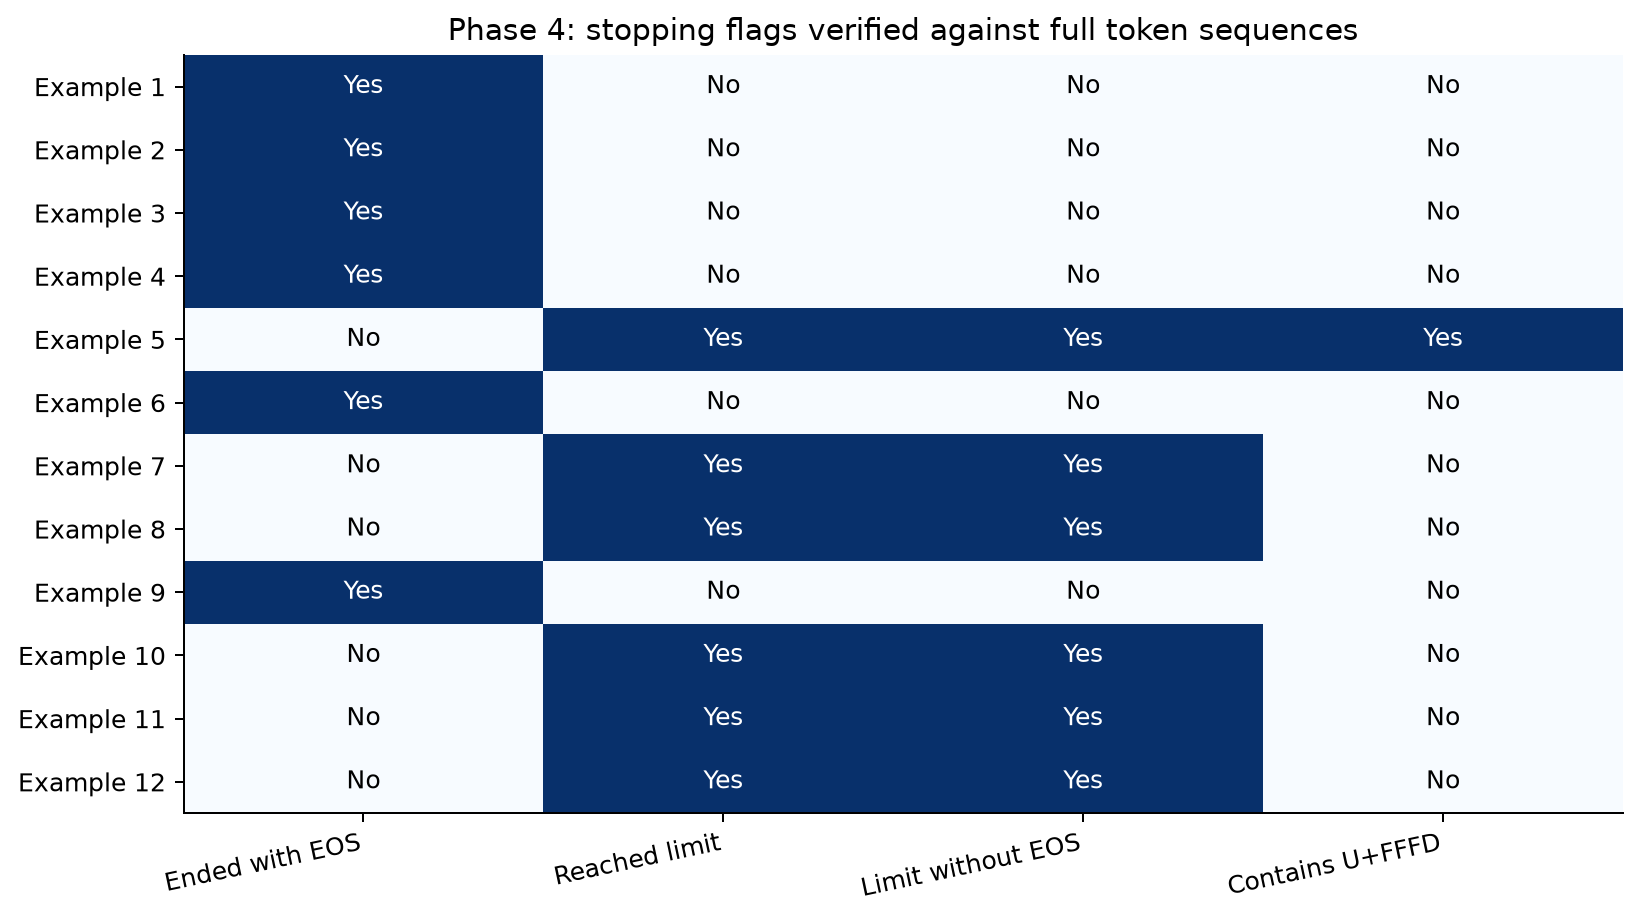

Six outputs end with EOS; six hit the cap without EOS. One capped output ends with U+FFFD. Its partial-byte ending is consistent with interrupted generation, but this does not establish a general encoding defect or justify deleting the character from scoring.



### 5. Measured inference memory

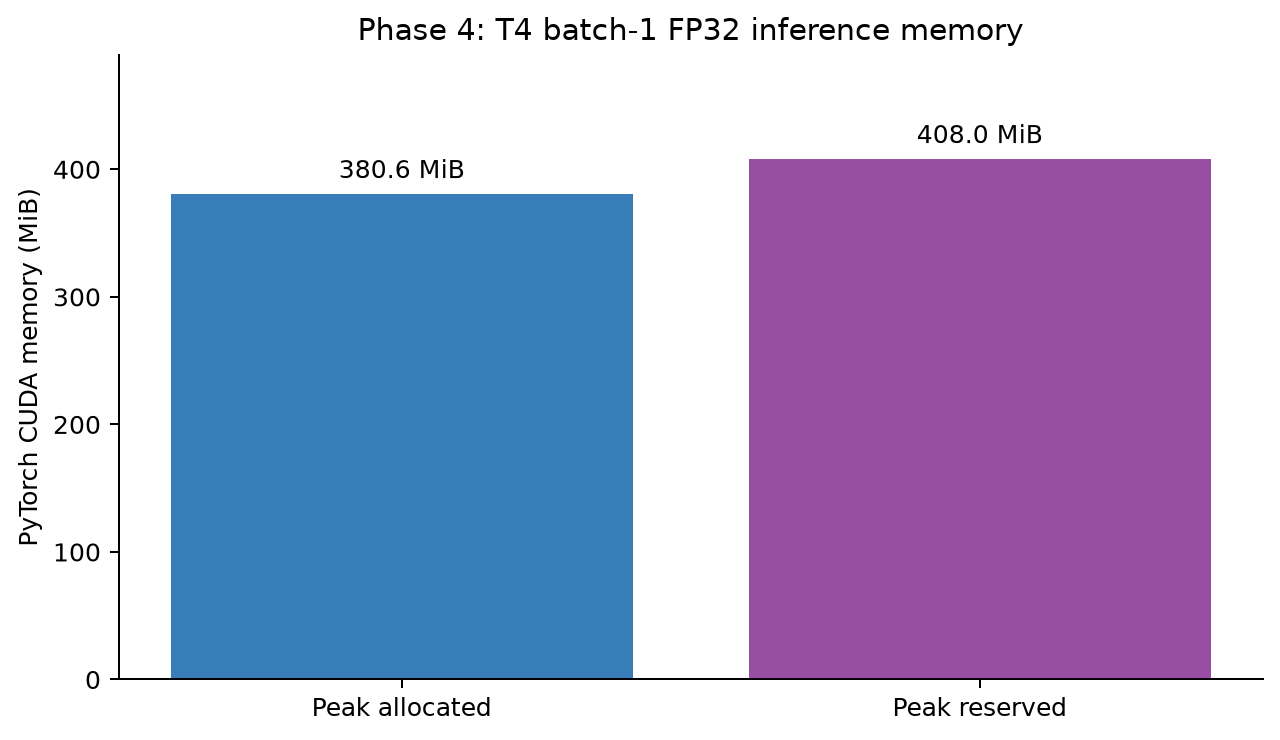

Batch-1 FP32 inference fits on the measured T4. Fine-tuning, longer batches, gradient memory and full-run throughput must be measured separately.



## Language-prefix observation

All 12 full sequences begin with `[50258, 50259, 50363]`, corresponding in the saved configuration to start-of-transcript, the English language token and no-timestamps. The notebook passes `language=None` and does not explicitly force English. **Unforced language is not token-free:** Whisper selected an English prefix automatically on these examples. Record this behavior in the baseline; it neither identifies Nyishi as English nor proves this is the sole cause of poor output. Do not silently invent a Nyishi token or change language settings to improve these smoke examples.

## Interpretation and next phase

**The model is operational but its current Nyishi transcription quality is poor.** Outputs are IPA-like, yet contain omissions, substitutions and extended repetition. Compatibility does not imply phonetic correctness. The 50% cap-hit rate describes these 12 deliberately varied training examples, not a population failure rate. No Nyishi fine-tuning has occurred.

No additional smoke-test rerun is required for the already-verified gates. Before a full baseline:

1. Save the executed Kaggle notebook for provenance when available; the source and exported-run version difference is documented.
2. Prepare and hash-check the frozen **732 validation clips / 1.881808 hours**, and verify ID/reference/audio alignment.
3. Verify corpus CER on known examples, combining marks and empty predictions. Apply NFD, outer trim and repeated ordinary-space collapse to both sides; keep spaces and all IPA marks.
4. Run a small validation preflight, then all validation rows with resumable exports. Retain cap-limited outputs, repetition, U+FFFD and empty/failed predictions. Report S/D/I, reference characters, evaluated counts/hours, runtime and failure flags. CER may exceed 100% when insertions dominate; do not cap it.
5. Keep the current checkpoint, software stack and greedy FP32 settings for the first baseline. Log automatic language prefixes and resolved begin-suppression settings. Any later decoding alternative is a named validation experiment.
6. After zero-shot validation, train a 1–2 hour supervised pilot and select by validation CER. Measure training memory/speed before expansion. Keep the **683 frozen test clips** for final evaluation.

### Historical correction

Earlier exports incorrectly treated Whisper's postprocessed tensor as full sequences, producing invalid zero EOS/cap flags. The corrected short-form `return_dict_in_generate=True` / `.sequences` route is now evidenced by the full tokens in this export. The historical run remains a record, not the current stopping result. [Pinned Transformers implementation](https://github.com/huggingface/transformers/blob/v4.57.1/src/transformers/models/whisper/generation_whisper.py).
